# Algorithm checks

Checks that our k-NN and Shapley code is correct, then compares the fast evaluator with the simple one, and reads the pilot that sets the minimum number of permutations. No test data is used.

## Setup
Run from the `notebooks/` folder. k-NN is written with NumPy only. `predict_knn` predicts a batch of points and `explain_knn_query` shows the vote for one point.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))  # so the notebook can import the project
import inspect
import numpy as np

import data_shapley.knn as knn_module
from data_shapley.knn import explain_knn_query, predict_knn

K = 3
print("Fixed project k:", K)
print("NumPy version:", np.__version__)

def show_vote(vote, labels):
    print(f"{'Row':>3} {'Label':>12} {'Distance':>12} {'Vote weight':>12}")
    for i, (label, distance, weight) in enumerate(zip(labels, vote.distances, vote.weights)):
        print(f"{i:>3} {str(label):>12} {distance:>12.6f} {weight:>12.6f}")
    print("Class totals (exact numerator / common denominator):")
    for label, numerator, total in zip(vote.classes, vote.vote_numerators, vote.votes):
        print(f"  {label}: {numerator}/{vote.denominator} = {total:.6f}")
    print(f"Total neighbor weight: {vote.vote_numerators.sum()}/{vote.denominator} = {vote.vote_numerators.sum() / vote.denominator:g}")
    print("Prediction:", vote.prediction)


Fixed project k: 3
NumPy version: 2.5.3


## The 3-NN rule
- Find the 3 closest training points by Euclidean distance.
- If several points tie at the third distance, they share the last vote.
- The class with the most votes wins. A tie goes to the class with the closest point, then to the first class in sorted order (Adelie, Chinstrap, Gentoo, or 0, 1).

Sharing tied votes means row order never decides the prediction.

## Distances by hand
From (0, 0), the point (3, 4) is at distance 5.

In [2]:
distance_X = np.array([[3.0, 4.0], [0.0, -2.0], [0.0, 0.0], [-6.0, 8.0]])
distance_y = np.array([0, 1, 0, 1])
distance_vote = explain_knn_query(distance_X, distance_y, np.array([0.0, 0.0]), k=K)
np.testing.assert_array_equal(distance_vote.distances, [5.0, 2.0, 0.0, 10.0])
np.testing.assert_array_equal(distance_vote.weights, [1.0, 1.0, 1.0, 0.0])
assert distance_vote.prediction == 0
show_vote(distance_vote, distance_y)


Row        Label     Distance  Vote weight
  0            0     5.000000     1.000000
  1            1     2.000000     1.000000
  2            0     0.000000     1.000000
  3            1    10.000000     0.000000
Class totals (exact numerator / common denominator):
  0: 2/1 = 2.000000
  1: 1/1 = 1.000000
Total neighbor weight: 3/1 = 3
Prediction: 0


## Plain majority
The closest point is class 1 but the next two are class 0, so class 0 wins 2 to 1.

In [3]:
majority_X = np.array([[1.0], [2.0], [3.0], [10.0]])
majority_y = np.array([1, 0, 0, 1])
majority_vote = explain_knn_query(majority_X, majority_y, np.array([0.0]), k=K)
np.testing.assert_array_equal(majority_vote.votes, [2.0, 1.0])
assert majority_vote.prediction == 0
show_vote(majority_vote, majority_y)


Row        Label     Distance  Vote weight
  0            1     1.000000     1.000000
  1            0     2.000000     1.000000
  2            0     3.000000     1.000000
  3            1    10.000000     0.000000
Class totals (exact numerator / common denominator):
  0: 2/1 = 2.000000
  1: 1/1 = 1.000000
Total neighbor weight: 3/1 = 3
Prediction: 0


## Shared vote at the boundary
Two points are closer than 2 and three sit exactly at 2. They share the last vote, 1/3 each. Class 0 gets 4/3 and class 1 gets 5/3, so class 1 wins.

In [4]:
fractional_X = np.array([[0.5, 0.0], [0.0, 1.0], [2.0, 0.0], [-2.0, 0.0], [0.0, -2.0], [3.0, 2.0]])
fractional_y = np.array([0, 1, 1, 1, 0, 0])
query = np.array([0.0, 0.0])
fractional_vote = explain_knn_query(fractional_X, fractional_y, query, k=K)
np.testing.assert_allclose(fractional_vote.weights, [1.0, 1.0, 1/3, 1/3, 1/3, 0.0])
np.testing.assert_array_equal(fractional_vote.vote_numerators, [4, 5])
assert fractional_vote.denominator == 3
assert fractional_vote.prediction == 1
show_vote(fractional_vote, fractional_y)


Row        Label     Distance  Vote weight
  0            0     0.500000     1.000000
  1            1     1.000000     1.000000
  2            1     2.000000     0.333333
  3            1     2.000000     0.333333
  4            0     2.000000     0.333333
  5            0     3.605551     0.000000
Class totals (exact numerator / common denominator):
  0: 4/3 = 1.333333
  1: 5/3 = 1.666667
Total neighbor weight: 9/3 = 3
Prediction: 1


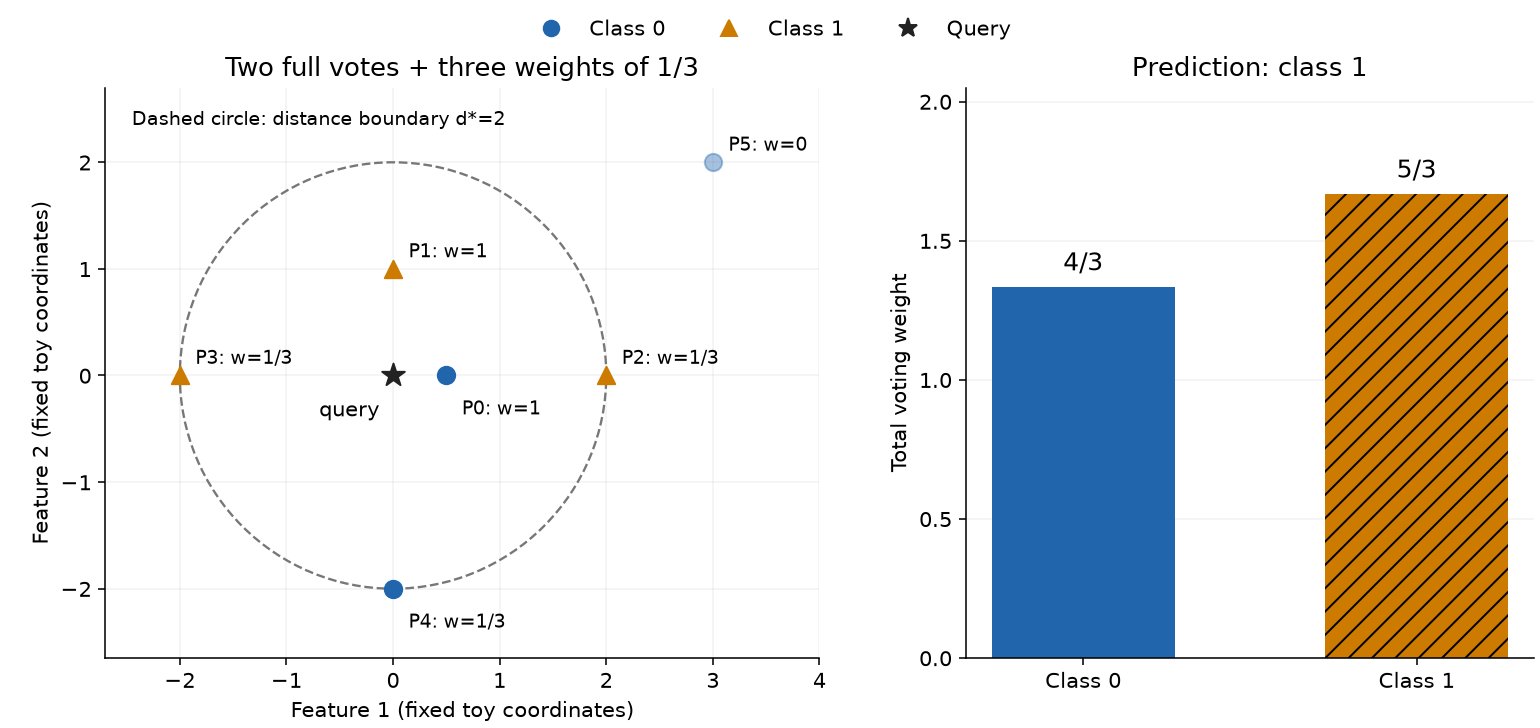

In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from io import BytesIO
from IPython.display import Image, display

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = {0: "#2166AC", 1: "#CC7A00"}
markers = {0: "o", 1: "^"}
fig, (ax, votes_ax) = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1.45, 1]}, layout="constrained")
ax.add_patch(Circle(query, fractional_vote.boundary_distance, fill=False, linestyle="--", linewidth=1.2, edgecolor="#777777"))
weight_labels = ["1", "1", "1/3", "1/3", "1/3", "0"]
offsets = [(8, -20), (8, 6), (8, 6), (8, 6), (8, -20), (8, 6)]
for i, (point, label, weight) in enumerate(zip(fractional_X, fractional_y, fractional_vote.weights)):
    ax.scatter(*point, s=80, marker=markers[int(label)], color=colors[int(label)], alpha=1 if weight > 0 else 0.4)
    ax.annotate(f"P{i}: w={weight_labels[i]}", point, xytext=offsets[i], textcoords="offset points", fontsize=10)
ax.scatter(*query, s=150, marker="*", color="#222222", zorder=5)
ax.annotate("query", query, xytext=(-38, -21), textcoords="offset points")
ax.text(-2.45, 2.35, "Dashed circle: distance boundary d*=2", fontsize=10)
ax.set(xlim=(-2.7, 4.0), ylim=(-2.65, 2.7), xlabel="Feature 1 (fixed toy coordinates)", ylabel="Feature 2 (fixed toy coordinates)", title="Two full votes + three weights of 1/3")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.15)
ax.set_axisbelow(True)

bars = votes_ax.bar(["Class 0", "Class 1"], fractional_vote.votes, color=[colors[0], colors[1]], width=0.55)
bars[1].set_hatch("//")
for bar, text in zip(bars, ("4/3", "5/3")):
    votes_ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.06, text, ha="center", fontsize=13)
votes_ax.set(ylim=(0, 2.05), ylabel="Total voting weight", title="Prediction: class 1")
votes_ax.set_yticks([0, 0.5, 1, 1.5, 2])
votes_ax.grid(axis="y", alpha=0.15)
votes_ax.set_axisbelow(True)
legend = [Line2D([], [], marker=markers[label], color=colors[label], linestyle="", label=f"Class {label}", markersize=8) for label in (0, 1)]
legend.append(Line2D([], [], marker="*", color="#222222", linestyle="", label="Query", markersize=10))
fig.legend(handles=legend, loc="outside upper center", ncol=3, frameon=False)
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=140, facecolor="white")
display(Image(data=buffer.getvalue()))
plt.close(fig)


## One or two training points
With one point its class wins. With two of different classes the closer one wins. An empty training set is not allowed.

In [6]:
one = predict_knn([[5.0]], np.array(["Gentoo"]), [[0.0], [10.0]], k=K)
np.testing.assert_array_equal(one, ["Gentoo", "Gentoo"])
print("One observation:", one.tolist())

two_nearest = explain_knn_query([[1.0], [2.0]], np.array(["Gentoo", "Adelie"]), np.array([0.0]), k=K)
assert two_nearest.prediction == "Gentoo"
print("Two classes tied at one vote each; nearest class wins:", two_nearest.prediction)

two_equidistant = explain_knn_query([[-1.0], [1.0]], np.array(["Gentoo", "Adelie"]), np.array([0.0]), k=K)
assert two_equidistant.prediction == "Adelie"
print("Equal votes and equal nearest distances; fixed order wins:", two_equidistant.prediction)

try:
    predict_knn(np.empty((0, 1)), np.array([], dtype=int), [[0.0]], k=K)
except ValueError as error:
    print("Expected empty-training rejection:", error)
else:
    raise AssertionError("Empty training data must be rejected.")


One observation: ['Gentoo', 'Gentoo']
Two classes tied at one vote each; nearest class wins: Gentoo
Equal votes and equal nearest distances; fixed order wins: Adelie
Expected empty-training rejection: k-NN requires at least one training observation; empty-set utility is separate.


## Exact vote ties
Gentoo and Adelie get one vote each, and nine Chinstrap points get 1/9 each, also one vote. Votes are compared as whole numbers so this stays a real tie. The closest point decides: Gentoo.

In [7]:
roundoff_X = np.array([[0.5], [1.0]] + [[2.0]] * 9)
roundoff_y = np.array(["Gentoo", "Adelie"] + ["Chinstrap"] * 9)
roundoff_vote = explain_knn_query(roundoff_X, roundoff_y, np.array([0.0]), k=K)
np.testing.assert_array_equal(roundoff_vote.vote_numerators, [9, 9, 9])
np.testing.assert_array_equal(roundoff_vote.votes, [1.0, 1.0, 1.0])
assert roundoff_vote.prediction == "Gentoo"
show_vote(roundoff_vote, roundoff_y)


Row        Label     Distance  Vote weight
  0       Gentoo     0.500000     1.000000
  1       Adelie     1.000000     1.000000
  2    Chinstrap     2.000000     0.111111
  3    Chinstrap     2.000000     0.111111
  4    Chinstrap     2.000000     0.111111
  5    Chinstrap     2.000000     0.111111
  6    Chinstrap     2.000000     0.111111
  7    Chinstrap     2.000000     0.111111
  8    Chinstrap     2.000000     0.111111
  9    Chinstrap     2.000000     0.111111
 10    Chinstrap     2.000000     0.111111
Class totals (exact numerator / common denominator):
  Adelie: 9/9 = 1.000000
  Chinstrap: 9/9 = 1.000000
  Gentoo: 9/9 = 1.000000
Total neighbor weight: 27/9 = 3
Prediction: Gentoo


## Row order does not matter
Four points at the same distance, two per class. All 24 row orders give the same prediction and weights.

In [8]:
from itertools import permutations

duplicate_X = np.array([[1.0, 0.0], [1.0, 0.0], [-1.0, 0.0], [-1.0, 0.0]])
duplicate_y = np.array([1, 1, 0, 0])
reference = explain_knn_query(duplicate_X, duplicate_y, np.zeros(2), k=K)
checked = 0
for order in permutations(range(4)):
    order = np.asarray(order)
    reordered = explain_knn_query(duplicate_X[order], duplicate_y[order], np.zeros(2), k=K)
    assert reordered.prediction == reference.prediction == 0
    np.testing.assert_array_equal(reordered.weights[np.argsort(order)], reference.weights)
    np.testing.assert_array_equal(reordered.vote_numerators, reference.vote_numerators)
    checked += 1
print("Checked row orderings:", checked)
print("Weights:", reference.weights.tolist())
print("Class votes:", reference.votes.tolist())
print("Prediction:", reference.prediction)


Checked row orderings: 24
Weights: [0.75, 0.75, 0.75, 0.75]
Class votes: [1.5, 1.5]
Prediction: 0


## The k-NN code
From [data_shapley/knn.py](../data_shapley/knn.py).

In [9]:
print(inspect.getsource(predict_knn))
print(inspect.getsource(knn_module._vote_for_query))


def predict_knn(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_queries: np.ndarray,
    k: int = 3,
) -> np.ndarray:
    """share boundary votes equally. break class ties by nearest member, then sorted label. use all points when fewer than k remain; reject empty training data."""
    train, labels, queries, k = _validate_inputs(X_train, y_train, X_queries, k)
    predictions = np.empty(len(queries), dtype=labels.dtype)
    for position, query in enumerate(queries):
        predictions[position] = _vote_for_query(train, labels, query, k).prediction
    return predictions

def _vote_for_query(train, labels, query, k):
    """include every boundary tie so row order cannot change the vote."""
    # hypot avoids overflow from squaring large distances
    with np.errstate(over="ignore", invalid="ignore"):
        distances = np.hypot.reduce(train - query, axis=1)
    if not np.isfinite(distances).all():
        raise ValueError("A Euclidean distance is not finite; check feature mag

## Accuracy and macro-F1
Checked against a hand calculation: accuracy 4/6, macro-F1 59/90. Only accuracy is used as the Shapley utility.

In [10]:
from data_shapley.metrics import accuracy, macro_f1, majority_class
from data_shapley.shapley import make_knn_utility, exact_shapley_subsets, exact_shapley_permutations
truth = np.array(['A','A','B','B','C','C'])
predicted = np.array(['A','A','A','B','B','C'])
print('Accuracy:', accuracy(truth, predicted), '= 4/6')
print('Macro-F1:', macro_f1(truth, predicted, ('A','B','C')), '= 59/90')
assert np.isclose(macro_f1(truth, predicted, ('A','B','C')), 59/90)
print('Absent-class example:', macro_f1([0,0], [0,0], (0,1,2)), '= 1/3')

Accuracy: 0.6666666666666666 = 4/6
Macro-F1: 0.6555555555555556 = 59/90
Absent-class example: 0.3333333333333333 = 1/3


## Marginal contributions
A point's contribution to a set S is V(S with the point) minus V(S). Its Shapley value is the average contribution over all orders. A small three-player example.

In [11]:
weights = np.array([0.3, -0.1, 0.0])
def teaching_game(s):
    return 0.2 + sum(weights[i] for i in s)
prefix = []
previous = teaching_game(prefix)
print('Player  Utility before  Utility after  Marginal')
for player in (1, 2, 0):
    prefix.append(player)
    current = teaching_game(prefix)
    print(f'{player:6d} {previous:15.3f} {current:14.3f} {current-previous:9.3f}')
    previous = current
print('All six orderings averaged:', exact_shapley_permutations(3, teaching_game))

Player  Utility before  Utility after  Marginal
     1           0.200          0.100    -0.100
     2           0.100          0.100     0.000
     0           0.100          0.400     0.300
All six orderings averaged: [ 0.3 -0.1  0. ]


## A six-point k-NN game
A toy game with six training points. Points 0 and 1 are identical. The empty-set score is the validation accuracy of the majority class of the clean training labels.

In [12]:
toy_X = np.array([[-2.],[-2.],[-1.],[1.],[2.],[2.]])
toy_y = np.array([0,0,0,1,1,0])
validation_X = np.array([[-2.],[-1.],[1.],[2.]])
validation_y = np.array([0,0,1,1])
utility = make_knn_utility(toy_X, toy_y, validation_X, validation_y, toy_y)
print('Player | coordinate | training label')
for i in range(6): print(i, toy_X[i,0], toy_y[i], sep='      ')
print('Validation coordinates:', validation_X.ravel())
print('Validation labels:', validation_y)
print('Baseline class:', majority_class(toy_y))
print('V(empty):', utility([]), 'V(full):', utility(range(6)))

Player | coordinate | training label
0      -2.0      0
1      -2.0      0
2      -1.0      0
3      1.0      1
4      2.0      1
5      2.0      0
Validation coordinates: [-2. -1.  1.  2.]
Validation labels: [0 0 1 1]
Baseline class: 0
V(empty): 0.5 V(full): 1.0


## Exact values two ways
Once with the subset formula (64 subsets) and once by averaging over all 720 orders. They must agree.

Reference: Ghorbani and Zou (2019), [Data Shapley](https://proceedings.mlr.press/v97/ghorbani19c.html). The paper's Equation 1 needs C = 1/n to match its Equation 2. We use the standard weights.

In [13]:
subset_values = exact_shapley_subsets(6, utility)
permutation_values = exact_shapley_permutations(6, utility)
print('Player    Subset formula    720 permutations    Difference')
for i, (a,b) in enumerate(zip(subset_values, permutation_values)):
    print(f'{i:6d} {a:17.10f} {b:19.10f} {a-b:13.2e}')
np.testing.assert_allclose(subset_values, permutation_values, rtol=0, atol=1e-12)
print('Sum:', subset_values.sum(), 'Required:', utility(range(6))-utility([]))
assert np.isclose(subset_values.sum(), utility(range(6))-utility([]))
assert np.isclose(subset_values[0], subset_values[1])

Player    Subset formula    720 permutations    Difference
     0      0.0291666667        0.0291666667      0.00e+00
     1      0.0291666667        0.0291666667      0.00e+00
     2      0.0291666667        0.0291666667      0.00e+00
     3      0.2166666667        0.2166666667      0.00e+00
     4      0.2291666667        0.2291666667     -2.78e-17
     5     -0.0333333333       -0.0333333333      0.00e+00
Sum: 0.5 Required: 0.5


## The toy values
Positive means the point raises validation accuracy on average. The identical points 0 and 1 get the same value.

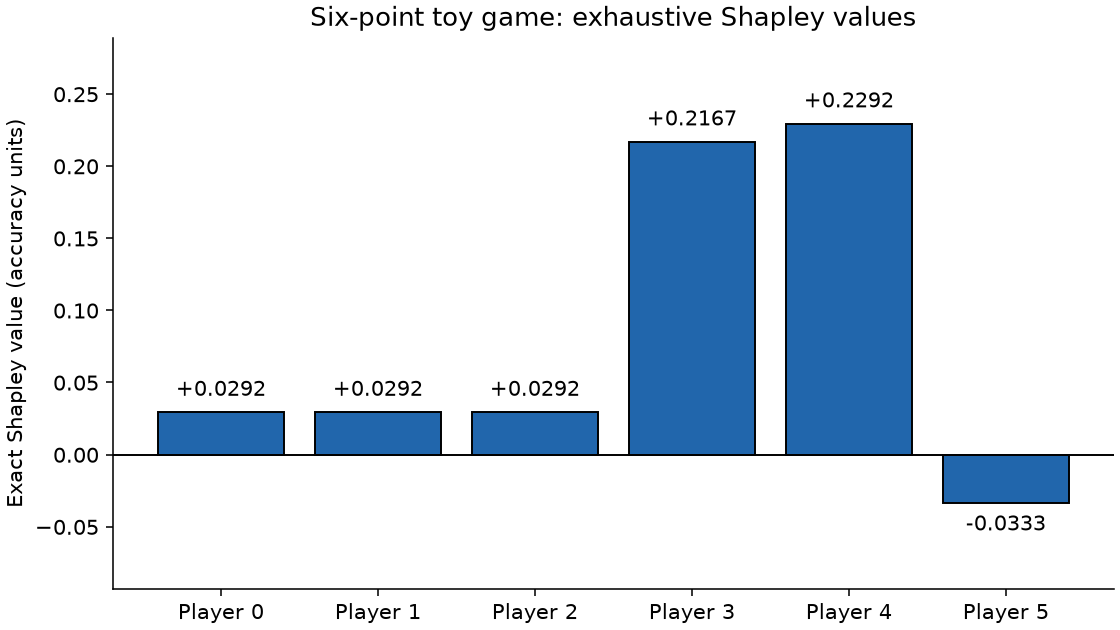

In [14]:
fig, ax = plt.subplots(figsize=(8,4.5), layout='constrained')
ax.bar(range(6), subset_values, color='#2166ac', edgecolor='black')
ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(range(6), [f'Player {i}' for i in range(6)])
ax.set_ylabel('Exact Shapley value (accuracy units)')
ax.set_title('Six-point toy game: exhaustive Shapley values')
ax.set_ylim(min(subset_values)-0.06, max(subset_values)+0.06)
for i, value in enumerate(subset_values):
    ax.text(i, value + (0.008 if value >= 0 else -0.008), f'{value:+.4f}', ha='center', va='bottom' if value >= 0 else 'top')
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=140, facecolor="white")
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Shapley properties
Checks symmetry, a null player and that the values add up to V(all) minus V(empty).

In [15]:
known_weights = np.array([2., 2., 0., -1., 0.5, 3.])
def additive(s): return 7 + sum(known_weights[i] for i in s)
def unanimity(s): return 0.4 + int({0,1,2}.issubset(s))
for method in (exact_shapley_subsets, exact_shapley_permutations):
    a, u = method(6, additive), method(6, unanimity)
    np.testing.assert_allclose(a, known_weights, atol=1e-12)
    np.testing.assert_allclose(u, [1/3,1/3,1/3,0,0,0], atol=1e-12)
    print(method.__name__, '\n  Additive:', a, '\n  Unanimity:', u)

exact_shapley_subsets 
  Additive: [ 2.   2.   0.  -1.   0.5  3. ] 
  Unanimity: [0.33333333 0.33333333 0.33333333 0.         0.         0.        ]
exact_shapley_permutations 
  Additive: [ 2.   2.   0.  -1.   0.5  3. ] 
  Unanimity: [0.33333333 0.33333333 0.33333333 0.         0.         0.        ]


The two exact methods agree and the properties hold.

## Monte Carlo sampling
Draw random orders of all points, add them one at a time and record each point's contribution. The estimate is the average. No order is cut short.

In [16]:
from data_shapley.shapley import estimate_shapley_naive, evaluate_permutations_naive

def interaction_game(s):
    return 2 + 2*(0 in s) - (2 in s) + 4*({0, 1}.issubset(s))
trace = evaluate_permutations_naive(3, interaction_game, [[2, 0, 1]])
print('Arrival order:', trace.permutations[0])
print('Step  Player  Utility before  Utility after  Contribution')
for position, player in enumerate(trace.permutations[0]):
    print(f'{position+1:4d} {player:7d} {trace.prefix_utilities[0,position]:15.3f} '
          f'{trace.prefix_utilities[0,position+1]:14.3f} {trace.marginals[0,player]:13.3f}')
print('Contributions by player 0,1,2:', trace.values)
np.testing.assert_array_equal(trace.values, [2, 4, -1])


Arrival order: [2 0 1]
Step  Player  Utility before  Utility after  Contribution
   1       2           2.000          1.000        -1.000
   2       0           1.000          3.000         2.000
   3       1           3.000          7.000         4.000
Contributions by player 0,1,2: [ 2.  4. -1.]


## Sampling the six-point game
Using the real k-NN utility.

In [17]:
demo_seed = 2606
sampled = estimate_shapley_naive(6, utility, 50, np.random.default_rng(demo_seed))
print('Player    Exact value    Estimate (M=50)    Error')
for player in range(6):
    print(f'{player:6d} {subset_values[player]:14.6f} {sampled.values[player]:18.6f} '
          f'{sampled.values[player]-subset_values[player]:12.6f}')
required_total = utility(range(6)) - utility([])
np.testing.assert_allclose(sampled.marginals.sum(1), required_total, rtol=0, atol=1e-12)
np.testing.assert_allclose(sampled.values.sum(), required_total, rtol=0, atol=1e-12)
print('Maximum per-permutation efficiency residual:',
      np.max(np.abs(sampled.marginals.sum(1) - required_total)))
replayed = evaluate_permutations_naive(6, utility, sampled.permutations)
np.testing.assert_array_equal(replayed.prefix_utilities, sampled.prefix_utilities)
print('Saved orders reproduce every prefix exactly.')


Player    Exact value    Estimate (M=50)    Error
     0       0.029167           0.020000    -0.009167
     1       0.029167           0.015000    -0.014167
     2       0.029167           0.050000     0.020833
     3       0.216667           0.275000     0.058333
     4       0.229167           0.165000    -0.064167
     5      -0.033333          -0.025000     0.008333
Maximum per-permutation efficiency residual: 0.0
Saved orders reproduce every prefix exactly.


## Sampling error
Ten seeds (6000 to 6009), up to 2048 orders each, compared with the exact values. The 64 subset scores are stored first to keep this fast; we check that this gives the same results as calling k-NN.

In [18]:
coalition_table = {
    frozenset(i for i in range(6) if mask & (1 << i)): utility(
        [i for i in range(6) if mask & (1 << i)])
    for mask in range(64)
}
lookup = coalition_table.__getitem__
lookup_trace = evaluate_permutations_naive(6, lookup, sampled.permutations)
np.testing.assert_array_equal(lookup_trace.prefix_utilities, sampled.prefix_utilities)
budgets = np.array([32, 128, 512, 2048])
mc_seeds = list(range(6000, 6010))
rmse = np.empty((len(mc_seeds), len(budgets)))
final_estimates = []
for seed_index, seed in enumerate(mc_seeds):
    run = estimate_shapley_naive(6, lookup, int(budgets[-1]), np.random.default_rng(seed))
    np.testing.assert_allclose(run.marginals.sum(1), required_total, rtol=0, atol=1e-12)
    for budget_index, budget in enumerate(budgets):
        estimate = run.marginals[:budget].mean(0)
        rmse[seed_index, budget_index] = np.sqrt(np.mean((estimate-subset_values)**2))
    final_estimates.append(run.values)
print('Seed    RMSE M=32    M=128       M=512       M=2048')
for seed, errors in zip(mc_seeds, rmse):
    print(f'{seed:4d}  ' + '  '.join(f'{error:.6f}' for error in errors))
mean_rmse = rmse.mean(0)
print('Mean  ' + '  '.join(f'{error:.6f}' for error in mean_rmse))
print('Mean absolute difference between symmetric players 0 and 1 at M=2048:',
      np.mean(np.abs(np.array(final_estimates)[:,0] - np.array(final_estimates)[:,1])))


Seed    RMSE M=32    M=128       M=512       M=2048
6000  0.023725  0.022515  0.006920  0.004459
6001  0.046454  0.030548  0.012355  0.003714
6002  0.027013  0.021516  0.007483  0.003912
6003  0.046976  0.023880  0.007742  0.004542
6004  0.030414  0.009221  0.005441  0.005077
6005  0.032858  0.036485  0.015880  0.003373
6006  0.033653  0.014662  0.005282  0.004358
6007  0.012159  0.017967  0.010921  0.004572
6008  0.021850  0.026123  0.014128  0.003105
6009  0.038556  0.018366  0.007092  0.004917
Mean  0.031366  0.022128  0.009324  0.004203
Mean absolute difference between symmetric players 0 and 1 at M=2048: 0.00574951171875


## Error against number of orders
Grey lines are single seeds and the blue line is their average. The error goes down as the number of orders grows.

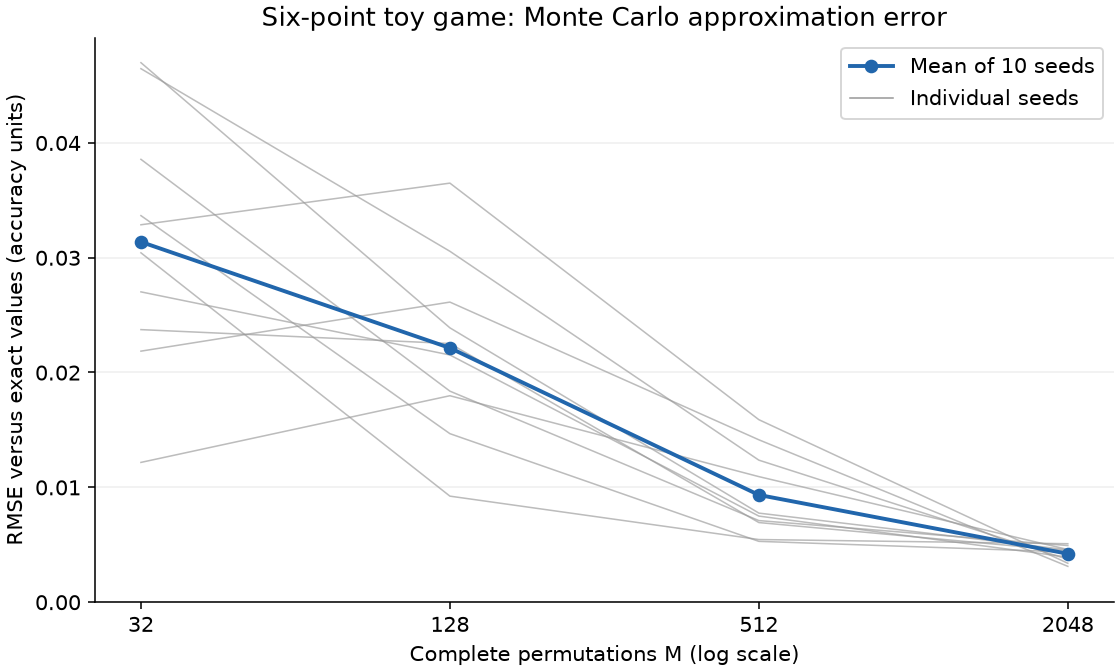

Mean RMSE: 0.031366 at M=32; 0.004203 at M=2048.
Individual increases between checkpoints: 3


In [19]:
fig, ax = plt.subplots(figsize=(8, 4.8), layout='constrained')
for errors in rmse:
    ax.plot(budgets, errors, color='#999999', linewidth=0.8, alpha=0.65)
ax.plot(budgets, mean_rmse, color='#2166ac', marker='o', linewidth=2, label='Mean of 10 seeds')
ax.plot([], [], color='#999999', linewidth=0.8, label='Individual seeds')
ax.set_xscale('log', base=2)
ax.set_xticks(budgets, [str(m) for m in budgets])
ax.set_ylim(bottom=0)
ax.set_xlabel('Complete permutations M (log scale)')
ax.set_ylabel('RMSE versus exact values (accuracy units)')
ax.set_title('Six-point toy game: Monte Carlo approximation error')
ax.grid(axis='y', alpha=0.2)
ax.legend()
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=140, facecolor='white')
display(Image(data=buffer.getvalue()))
plt.close(fig)
print(f'Mean RMSE: {mean_rmse[0]:.6f} at M=32; {mean_rmse[-1]:.6f} at M=2048.')
print('Individual increases between checkpoints:', int(np.sum(np.diff(rmse, axis=1) > 0)))


The sampler matches the exact values on the toy game.

## Fast evaluator
`SortedKNNGame` gives the same results as the simple version but sorts the distances once instead of recomputing them for every prefix.

In [20]:
from data_shapley.shapley import SortedKNNGame
fast_game = SortedKNNGame(toy_X, toy_y, validation_X, validation_y, toy_y)
fast_trace = fast_game.evaluate(sampled.permutations)
for field in ('permutations', 'prefix_utilities', 'marginals', 'values'):
    np.testing.assert_array_equal(getattr(sampled, field), getattr(fast_trace, field))
print('Every toy prefix, marginal and final estimate is exactly equal.')


Every toy prefix, marginal and final estimate is exactly equal.


## Speed check
Seed 100, the three conditions, six shared orders each. Results must be exactly equal; the timing is only a rough guide.

In [21]:
import json
import platform
import time
from data_shapley.data import (load_penguins, make_data_rngs, split_penguins,
    standardize_split, generate_gaussian_split, corrupt_training_labels, CLASS_LABELS)

bench_rngs, bench_manifest = make_data_rngs(100)
penguin_split, _ = standardize_split(split_penguins(
    load_penguins('../data/raw/penguins.csv'), bench_rngs['penguins_split']))
gaussian_split, _ = standardize_split(generate_gaussian_split(
    bench_rngs['synthetic_train'], bench_rngs['synthetic_validation'], bench_rngs['synthetic_test']))
penguin_noise = corrupt_training_labels(penguin_split.train, 41, CLASS_LABELS, bench_rngs['penguins_noise'])
gaussian_noise = corrupt_training_labels(gaussian_split.train, 30, (0, 1), bench_rngs['synthetic_noise'])
conditions = [('clean_penguins', penguin_split, penguin_split.train.y),
              ('noisy_penguins', penguin_split, penguin_noise.training.y),
              ('noisy_gaussian', gaussian_split, gaussian_noise.training.y)]
benchmark = {'run_seed': 100, 'python': platform.python_version(),
             'numpy': np.__version__, 'platform': platform.platform(),
             'processor': platform.processor(), 'data_seed_manifest': bench_manifest,
             'test_scored': False, 'conditions': {}}
for condition_index, (name, split, observed_y) in enumerate(conditions):
    args = (split.train.X, observed_y, split.validation.X, split.validation.y, split.train.y)
    start = time.perf_counter(); reference = make_knn_utility(*args)
    naive_setup = time.perf_counter() - start
    start = time.perf_counter(); optimized = SortedKNNGame(*args)
    fast_setup = time.perf_counter() - start
    seed = np.random.SeedSequence(100, spawn_key=(7, condition_index))
    generator = np.random.default_rng(seed)
    warmup = np.array([generator.permutation(optimized.n)])
    evaluate_permutations_naive(optimized.n, reference, warmup)
    optimized.evaluate(warmup)
    orders = np.array([generator.permutation(optimized.n) for _ in range(6)])
    durations = {'naive': [], 'optimized': []}
    prefix_count = 0
    for batch in range(3):
        shared = orders[2*batch:2*batch+2]
        outputs = {}
        methods = ['naive', 'optimized'] if batch % 2 == 0 else ['optimized', 'naive']
        for method in methods:
            start = time.perf_counter()
            outputs[method] = (evaluate_permutations_naive(optimized.n, reference, shared)
                               if method == 'naive' else optimized.evaluate(shared))
            durations[method].append(time.perf_counter()-start)
        for field in ('permutations', 'prefix_utilities', 'marginals', 'values'):
            np.testing.assert_array_equal(getattr(outputs['naive'], field), getattr(outputs['optimized'], field))
        prefix_count += outputs['naive'].prefix_utilities.size
        print(name, 'batch', batch+1, 'exact equality verified', flush=True)
    naive_seconds, fast_seconds = [float(np.median(durations[key])/2) for key in ['naive','optimized']]
    benchmark['conditions'][name] = {'n': optimized.n, 'q': len(split.validation.y),
        'naive_setup_seconds': naive_setup, 'optimized_setup_seconds': fast_setup,
        'two_permutation_batch_seconds': durations, 'naive_seconds_per_permutation': naive_seconds,
        'optimized_seconds_per_permutation': fast_seconds, 'speedup': naive_seconds/fast_seconds,
        'prefixes_compared': prefix_count, 'exact_equality': True,
        'permutation_seed': {'entropy': 100, 'spawn_key': [7,condition_index]},
        'warmup_order': warmup.tolist(), 'timed_orders': orders.tolist()}
print('Condition        Naive sec/draw   Optimized sec/draw   Speedup')
for name, row in benchmark['conditions'].items():
    print(f"{name:16s} {row['naive_seconds_per_permutation']:14.4f} "
          f"{row['optimized_seconds_per_permutation']:20.4f} {row['speedup']:9.2f}x")

clean_penguins batch 1 exact equality verified


clean_penguins batch 2 exact equality verified


clean_penguins batch 3 exact equality verified


noisy_penguins batch 1 exact equality verified


noisy_penguins batch 2 exact equality verified


noisy_penguins batch 3 exact equality verified


noisy_gaussian batch 1 exact equality verified


noisy_gaussian batch 2 exact equality verified


noisy_gaussian batch 3 exact equality verified


Condition        Naive sec/draw   Optimized sec/draw   Speedup
clean_penguins           0.9718               0.0483     20.10x
noisy_penguins           0.9985               0.0543     18.38x
noisy_gaussian           0.6810               0.0410     16.59x


The fast evaluator gives identical results. Timings depend on the machine.

## Pilot
The pilot (`python -m data_shapley.pilot`) uses seed 100 and two independent runs per condition. It compares them at 50, 100, 200 and 500 permutations. If any condition has Spearman below 0.90 or a bottom-20% overlap below 0.80 at 500, it continues to 1000 and 2000. The largest number reached is the minimum for every study run. Validation data only.

In [22]:
pilot_path = Path('../results/pilot/pilot_seed100.json')
pilot = json.loads(pilot_path.read_text(encoding='utf-8'))
assert pilot['status'] == 'complete' and not pilot['test_scored']
print('Condition         M/stream    Spearman   Kendall-b   Overlap10   Overlap20   Mean abs diff')
for name, record in pilot['conditions'].items():
    for row in record['rows']:
        print(f"{name:16s} {row['M_per_stream']:8d} {row['spearman']:11.3f} "
              f"{row['kendall_tau_b']:11.3f} {row['bottom']['0.1']['overlap_fraction']:11.3f} "
              f"{row['bottom']['0.2']['overlap_fraction']:11.3f} {row['mean_absolute_value_difference']:15.6f}")
print('Recorded sampling plus diagnostic wall time (minutes):',
      round(pilot['sampling_and_diagnostics_wall_seconds']/60,2))
print('Minimum permutations per study run: M_min =', pilot['M_selected'])


Condition         M/stream    Spearman   Kendall-b   Overlap10   Overlap20   Mean abs diff
clean_penguins         50       0.001       0.001       0.190       0.220        0.005989
clean_penguins        100       0.109       0.074       0.143       0.317        0.004667
clean_penguins        200       0.228       0.157       0.238       0.268        0.003070
clean_penguins        500       0.308       0.213       0.333       0.415        0.001981
clean_penguins       1000       0.293       0.200       0.286       0.366        0.001463
clean_penguins       2000       0.418       0.294       0.429       0.488        0.001017
noisy_penguins         50       0.526       0.379       0.667       0.732        0.006109
noisy_penguins        100       0.650       0.483       0.762       0.829        0.004273
noisy_penguins        200       0.711       0.538       0.810       0.902        0.003031
noisy_penguins        500       0.793       0.632       0.905       0.951        0.002003
noisy_pen

## Agreement between the two runs
How much the two runs agree on the lowest-value points.

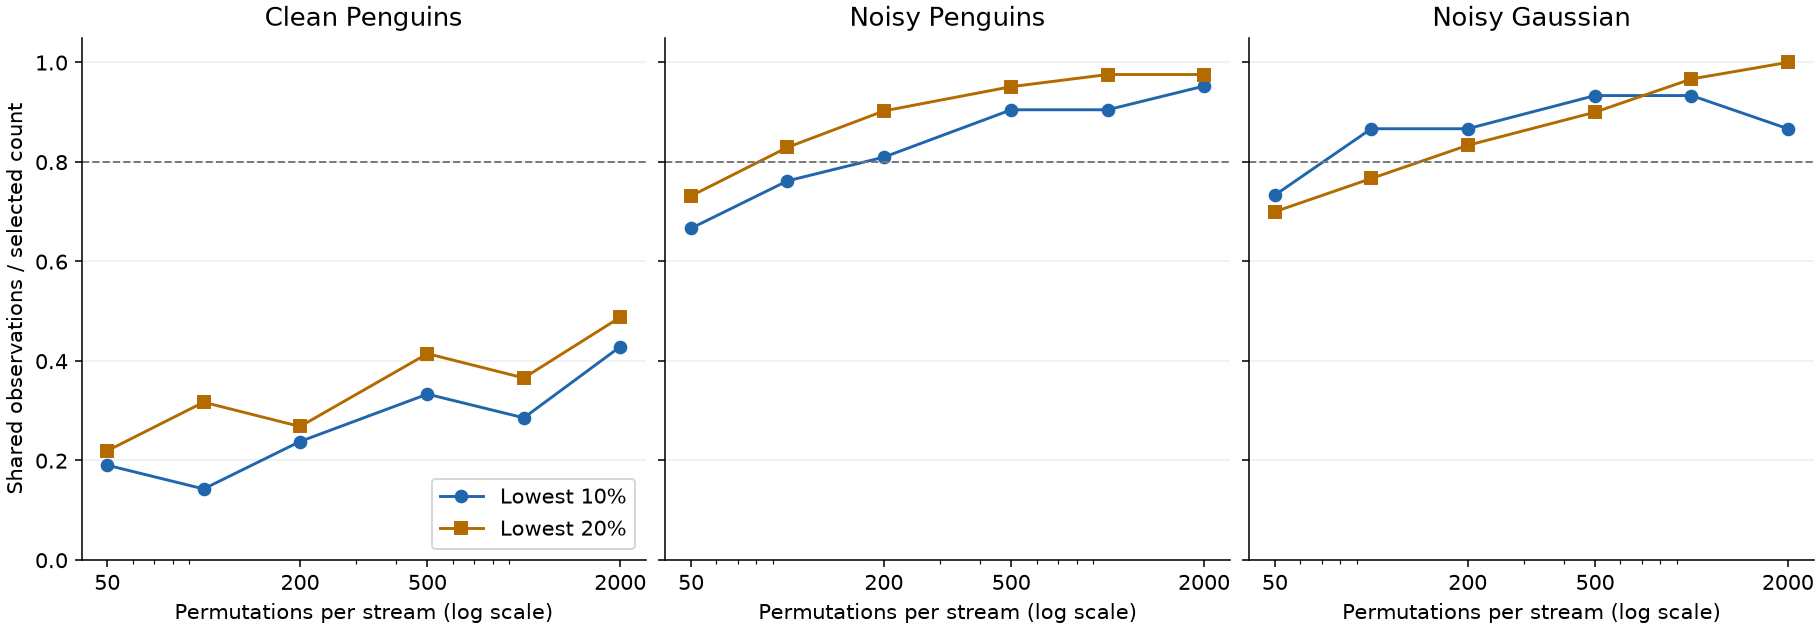

In [23]:
fig, axes = plt.subplots(1,3,figsize=(13,4.5),layout='constrained',sharey=True)
for ax, (name, record) in zip(axes, pilot['conditions'].items()):
    budgets = [row['M_per_stream'] for row in record['rows']]
    for fraction,color,marker,label in [('0.1','#2166ac','o','Lowest 10%'),('0.2','#b36b00','s','Lowest 20%')]:
        overlaps = [row['bottom'][fraction]['overlap_fraction'] for row in record['rows']]
        ax.plot(budgets, overlaps, color=color, marker=marker, label=label)
    ax.axhline(.8, color='#777777', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_xticks([50,200,500,budgets[-1]], [str(x) for x in [50,200,500,budgets[-1]]])
    ax.set_ylim(0,1.05)
    ax.set_title(name.replace('_',' ').title())
    ax.set_xlabel('Permutations per stream (log scale)')
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Shared observations / selected count')
axes[0].legend(loc='lower right')
buffer=BytesIO()
fig.savefig(buffer,format='png',dpi=140,facecolor='white')
display(Image(data=buffer.getvalue()))
plt.close(fig)


## Pilot result
Clean Penguins did not reach the targets at 500, so the pilot went on to 2000. Every study run uses at least **2000** permutations, then continues in steps of 100 until the convergence rule of Ghorbani & Zou (2019) is met: the average relative change of the values over the last 100 permutations is below 0.05 (cap 20000).